# MNIST CFG network: train from scratch, then sample with guidance

Trains the MNIST guidance lab's class-conditional U-Net from scratch on MNIST's 60,000 training digits. For a
random 10% of training examples the label is replaced with 10 ("no label"), so one network learns both the
conditional and the unconditional estimate. Then samples 1,000 digits (100 per digit) for w = 0, 1, 2, 4 and
measures label accuracy with the lab's frozen digit classifier, and FID on that classifier's 128 features,
against MNIST's 10,000 test digits.

**Before running:** open `guidance_mnist.ipynb` in this folder and run its first three code cells (install,
`%%writefile mnist_guidance_lab.py`, and the weights download). This notebook reuses that file's `UNet`, sampler
and classifier, and `evaluator.pt`.

In [1]:
import json, time, itertools
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import linalg
import torchvision
import mnist_guidance_lab as mg

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
QUICK = DEVICE != "cuda"                       # True on a laptop: a short run to test the code only
EPOCHS = 1 if QUICK else 20                    # passes over the 60,000 training digits
BATCH, LR, LABEL_DROPOUT = 128, 5e-4, 0.1
W = [0, 1, 2, 4]
N_EVAL = 200 if QUICK else 1000                # generated digits per w (balanced: N_EVAL / 10 per digit)
FIG, RES, OUT = Path("../figures"), Path("../results"), Path("outputs")
for d in (FIG, RES, OUT):
    d.mkdir(exist_ok=True)
print(f"device {DEVICE}, QUICK = {QUICK}, {EPOCHS} epochs, {N_EVAL} images per w")

# Save every figure shown in this notebook to figures/mnist_00.png, mnist_01.png, ...
_n, _orig_show = itertools.count(), plt.show
def _show_and_save(*a, **k):
    plt.savefig(FIG / f"mnist_{next(_n):02d}.png", dpi=150, bbox_inches="tight")
    _orig_show(*a, **k)
plt.show = _show_and_save

device cuda, QUICK = False, 20 epochs, 1000 images per w


## Data
MNIST from `torchvision.datasets.MNIST`, scaled to [-1, 1] like the lab's sampler output.

In [2]:
def load_mnist(train):
    ds = torchvision.datasets.MNIST("downloads/mnist", train=train, download=True)
    return (ds.data.float() / 127.5 - 1).unsqueeze(1), ds.targets.clone()

x_train, y_train = load_mnist(True)
x_test, y_test = load_mnist(False)
print("train", tuple(x_train.shape), "test", tuple(x_test.shape))

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [00:00<00:00, 14027437.38it/s]


Extracting downloads/mnist/MNIST/raw/train-images-idx3-ubyte.gz to downloads/mnist/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 660672.88it/s]


Extracting downloads/mnist/MNIST/raw/train-labels-idx1-ubyte.gz to downloads/mnist/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1648877/1648877 [00:00<00:00, 4054412.64it/s]


Extracting downloads/mnist/MNIST/raw/t10k-images-idx3-ubyte.gz to downloads/mnist/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4542/4542 [00:00<00:00, 2358614.43it/s]


Extracting downloads/mnist/MNIST/raw/t10k-labels-idx1-ubyte.gz to downloads/mnist/MNIST/raw

train (60000, 1, 28, 28) test (10000, 1, 28, 28)


## Training

The lab's convention: x0 is noise, x1 is the digit, and $x_t = \alpha_t x_1 + \sigma_t x_0$ with
$\alpha_t = \sin(\pi t/2)$, $\sigma_t = \cos(\pi t/2)$. The network predicts the clean digit $x_1$ from
$(x_t, t, \text{label})$, and the loss is the squared error of that prediction. Sampling uses an exponential
moving average (EMA) of the weights.

about 6.7 min for 9360 updates
epoch 1/20: loss 0.1026, 0.3 min so far
epoch 2/20: loss 0.0719, 0.6 min so far
epoch 3/20: loss 0.0683, 0.9 min so far
epoch 4/20: loss 0.0665, 1.2 min so far
epoch 5/20: loss 0.0658, 1.6 min so far
epoch 6/20: loss 0.0646, 1.9 min so far
epoch 7/20: loss 0.0641, 2.2 min so far
epoch 8/20: loss 0.0637, 2.5 min so far
epoch 9/20: loss 0.0631, 2.8 min so far
epoch 10/20: loss 0.0633, 3.1 min so far
epoch 11/20: loss 0.0633, 3.4 min so far
epoch 12/20: loss 0.0625, 3.7 min so far
epoch 13/20: loss 0.0624, 4.0 min so far
epoch 14/20: loss 0.0628, 4.4 min so far
epoch 15/20: loss 0.0619, 4.7 min so far
epoch 16/20: loss 0.0621, 5.0 min so far
epoch 17/20: loss 0.0621, 5.3 min so far
epoch 18/20: loss 0.0618, 5.6 min so far
epoch 19/20: loss 0.0611, 5.9 min so far
epoch 20/20: loss 0.0610, 6.2 min so far


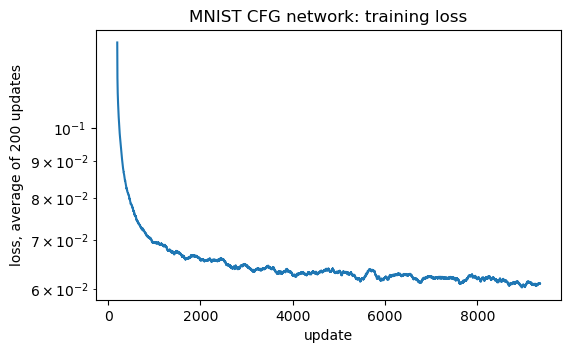

In [4]:
torch.manual_seed(0)
net = mg.UNet(ch=64).to(DEVICE).train()
ema = mg.UNet(ch=64).to(DEVICE).eval().requires_grad_(False)
ema.load_state_dict(net.state_dict())
opt = torch.optim.Adam(net.parameters(), lr=LR)
steps_per_epoch = len(x_train) // BATCH
total = EPOCHS * steps_per_epoch if not QUICK else 200
losses, t0, step = [], time.time(), 0

for epoch in range(EPOCHS):
    perm = torch.randperm(len(x_train))
    for b in range(steps_per_epoch):
        idx = perm[b * BATCH:(b + 1) * BATCH]
        x1, y = x_train[idx].to(DEVICE), y_train[idx].to(DEVICE)
        y = torch.where(torch.rand(len(y), device=DEVICE) < LABEL_DROPOUT, torch.full_like(y, 10), y)
        t = torch.rand(len(x1), device=DEVICE) * 0.999           # avoid t = 1 exactly (sigma = 0)
        a, s = mg.alpha_sigma(t)
        x0 = torch.randn_like(x1)
        xt = a[:, None, None, None] * x1 + s[:, None, None, None] * x0
        loss = F.mse_loss(net(xt, t, y), x1)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        with torch.no_grad():
            decay = 0.99 if step < 1000 else 0.999
            for pe, p in zip(ema.parameters(), net.parameters()):
                pe.lerp_(p, 1 - decay)
        losses.append(loss.item())
        step += 1
        if step == 100:
            print(f"about {(time.time() - t0) / 100 * total / 60:.1f} min for {total} updates", flush=True)
        if step >= total:
            break
    print(f"epoch {epoch + 1}/{EPOCHS}: loss {np.mean(losses[-steps_per_epoch:]):.4f}, "
          f"{(time.time() - t0) / 60:.1f} min so far", flush=True)
    if step >= total:
        break

torch.save({"ch": 64, "state": ema.state_dict()}, OUT / "mnist_cfg_generator.pt")
k = min(200, len(losses))
plt.figure(figsize=(6, 3.5))
plt.plot(range(k - 1, len(losses)), np.convolve(losses, np.ones(k) / k, mode="valid"))
plt.yscale("log"); plt.xlabel("update"); plt.ylabel(f"loss, average of {k} updates")
plt.title("MNIST CFG network: training loss")
plt.show()

In [5]:
@torch.no_grad()
def features(x, bs=500):
    return torch.cat([evaluator(x[i:i + bs].to(DEVICE))[1].double().cpu() for i in range(0, len(x), bs)]).numpy()

def gaussian(f):
    return f.mean(0), np.cov(f, rowvar=False)

def frechet(mu1, s1, mu2, s2):
    eps = 1e-6 * np.eye(len(s1))                    # keeps the square root stable if a feature never fires
    covmean = linalg.sqrtm((s1 + eps) @ (s2 + eps)).real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))

evaluator = mg.Evaluator().to(DEVICE)              # the lab's frozen digit classifier
evaluator.load_state_dict(torch.load("evaluator.pt", map_location="cpu", weights_only=True)["state"])
evaluator.eval().requires_grad_(False)
MU_REF, SIGMA_REF = gaussian(features(x_test))

g = torch.Generator().manual_seed(0)
real = x_train[torch.randperm(len(x_train), generator=g)[:N_EVAL]]
results = {"real": {"accuracy": None, "fid": frechet(*gaussian(features(real)), MU_REF, SIGMA_REF)}}
print(f"real training digits ({N_EVAL}): FID {results['real']['fid']:.2f}")

labels = torch.arange(N_EVAL) % 10                # balanced requests: image i asks for digit i mod 10
samples = {}
for w in W:
    images, _ = mg.sample(ema, N_EVAL, labels, DEVICE, steps=16, w=float(w), seed=0)
    acc, conf = mg.classification(evaluator, images, labels, DEVICE)
    results[w] = {"accuracy": acc, "confidence": conf,
                  "fid": frechet(*gaussian(features(images)), MU_REF, SIGMA_REF)}
    samples[w] = images
    print(f"w = {w}: accuracy {acc:6.1%}   FID {results[w]['fid']:7.2f}", flush=True)

(RES / f"mnist_cfg_n{N_EVAL}.json").write_text(json.dumps(
    {"n_images": N_EVAL, "epochs": EPOCHS, "results": {str(k): v for k, v in results.items()}}, indent=2))

real training digits (1000): FID 19.19
w = 0: accuracy  10.5%   FID  136.01
w = 1: accuracy  97.4%   FID   22.56
w = 2: accuracy 100.0%   FID   91.31
w = 4: accuracy 100.0%   FID  220.49


588

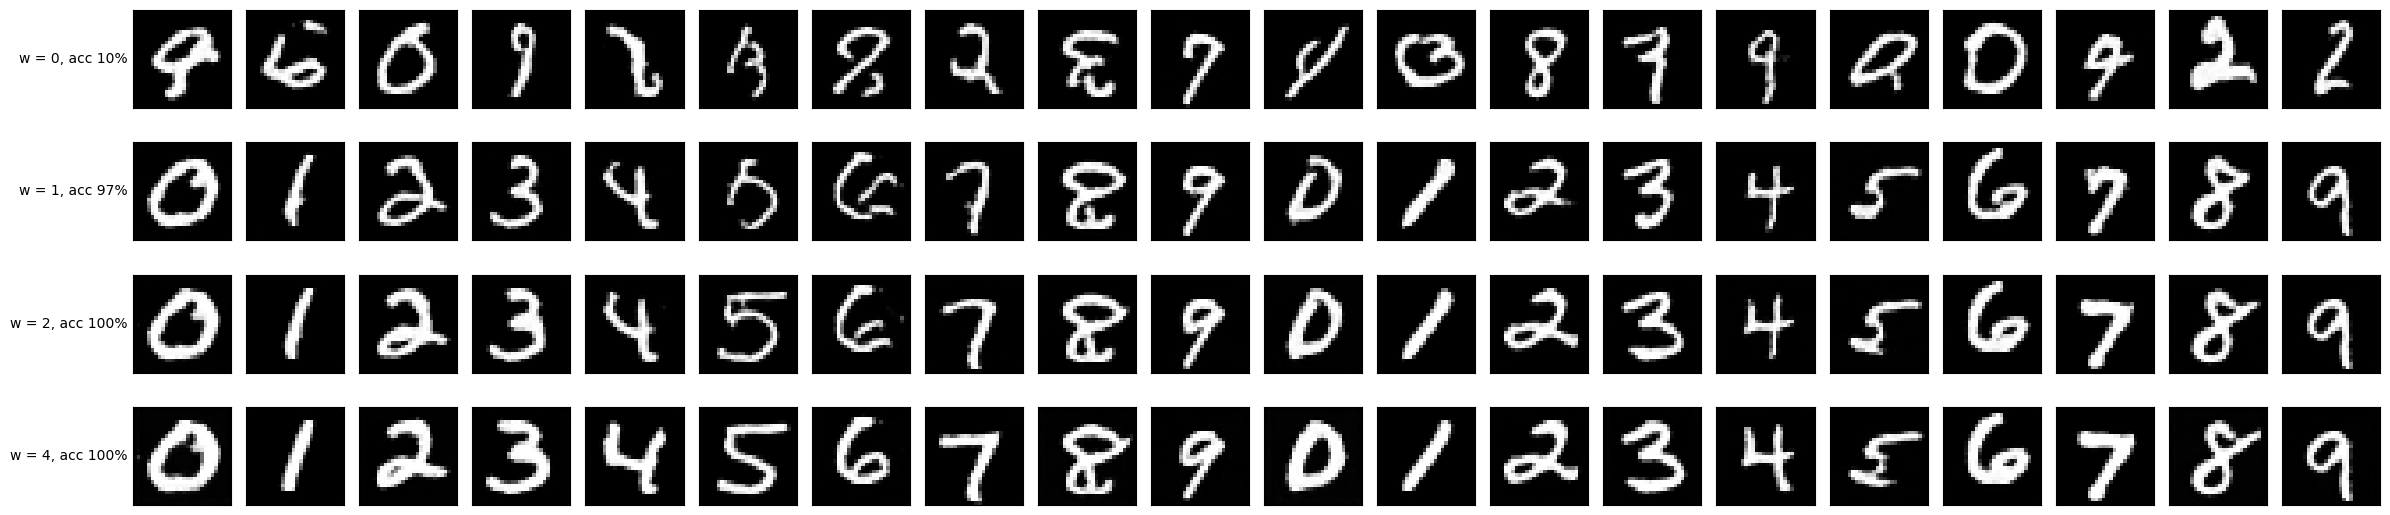

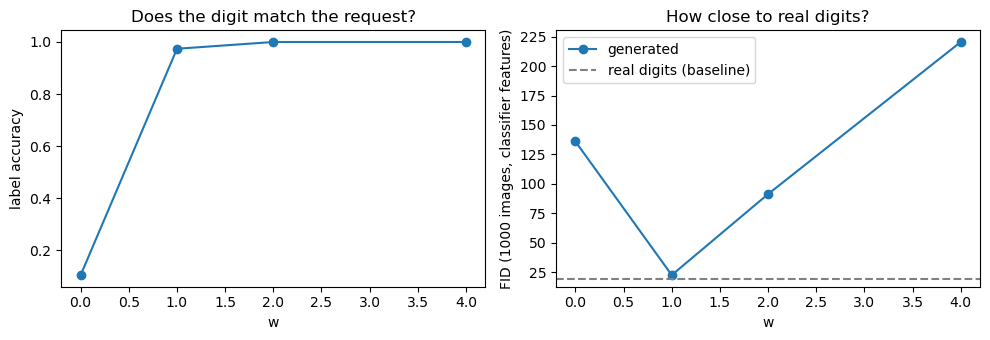

In [6]:
# One row per w, the same starting noise in each column; column j requests digit j mod 10.
mg.grid({f"w = {w}, acc {results[w]['accuracy']:.0%}": samples[w][:20] for w in W}, count=20)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(W, [results[w]["accuracy"] for w in W], marker="o")
axes[0].set(xlabel="w", ylabel="label accuracy", title="Does the digit match the request?")
axes[1].plot(W, [results[w]["fid"] for w in W], marker="o", label="generated")
axes[1].axhline(results["real"]["fid"], color="0.5", ls="--", label="real digits (baseline)")
axes[1].set(xlabel="w", ylabel=f"FID ({N_EVAL} images, classifier features)", title="How close to real digits?")
axes[1].legend()
fig.tight_layout()
plt.show()